In [ ]:
results_df.to_csv("../results/model_metrics.csv")
cv_results_df.to_csv("../results/cross_validation_metrics.csv")

In [46]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro"
        ]
    )

    cv_results[model_name] = {
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro Precision": scores["test_precision_macro"].mean(),
        "Mean Macro Recall": scores["test_recall_macro"].mean(),
        "Mean Macro F1": scores["test_f1_macro"].mean(),
        "Macro F1 Std": scores["test_f1_macro"].std()
    }

cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

,Mean Accuracy,Accuracy Std,Mean Macro Precision,Mean Macro Recall,Mean Macro F1,Macro F1 Std
Decision Tree,0.933333,0.014907,0.901628,0.903844,0.889693,0.032099
Random Forest,0.940000,0.022608,0.908039,0.905801,0.898783,0.043406


In [47]:
results_df.to_csv("../results/model_metrics.csv")

In [48]:
display(results_df)

,Accuracy,Macro Precision,Macro Recall,Macro F1
Decision Tree,0.933333,0.92,0.92,0.9
Random Forest,0.933333,0.92,0.92,0.9


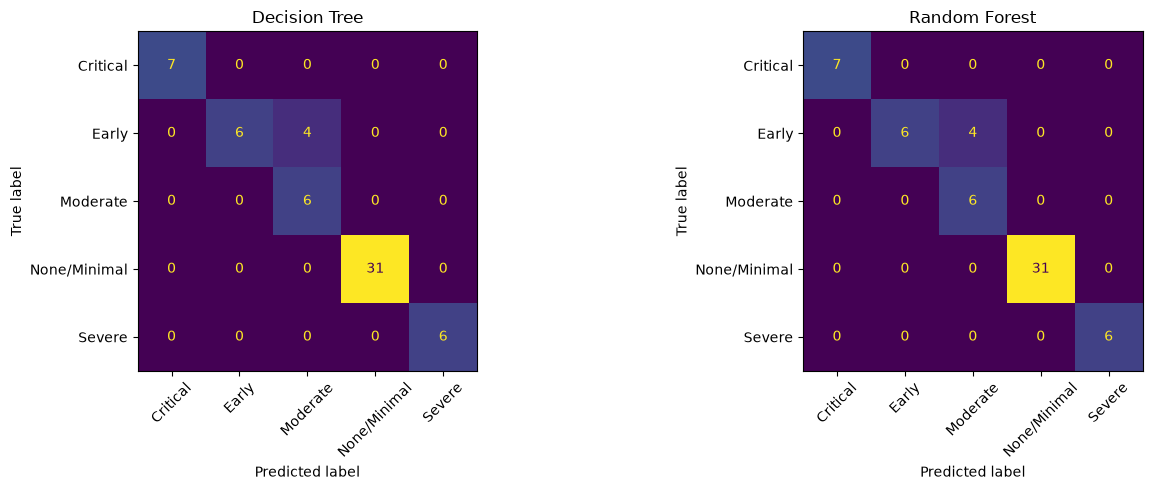

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for axis, (model_name, predictions) in zip(
    axes,
    predictions_by_model.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        ax=axis,
        xticks_rotation=45,
        colorbar=False
    )

    axis.set_title(model_name)

plt.tight_layout()
plt.show()

Confusion Matrices

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Features selected for the first experiment
features = [
    "avg_daily_sm_hours",
    "avg_daily_screen_time_hours",
    "doomscrolling_frequency",
    "late_night_scrolling",
    "avg_sleep_hours",
    "task_switching_frequency"
]

target = "productivity_decline_score"

X = df[features]
y = df[target]

# Separate numerical and categorical columns
numeric_features = [
    "avg_daily_sm_hours",
    "avg_daily_screen_time_hours",
    "avg_sleep_hours"
]

categorical_features = [
    "doomscrolling_frequency",
    "late_night_scrolling",
    "task_switching_frequency"
]

# Split the data while preserving the target-category proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Two models being compared
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        class_weight="balanced",
        random_state=42
    )
}

results = {}
predictions_by_model = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    predictions_by_model[model_name] = predictions

    results[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    }

    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results).T
display(results_df)

Decision Tree
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00         7
       Early       1.00      0.60      0.75        10
    Moderate       0.60      1.00      0.75         6
None/Minimal       1.00      1.00      1.00        31
      Severe       1.00      1.00      1.00         6

    accuracy                           0.93        60
   macro avg       0.92      0.92      0.90        60
weighted avg       0.96      0.93      0.93        60

Random Forest
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00         7
       Early       1.00      0.60      0.75        10
    Moderate       0.60      1.00      0.75         6
None/Minimal       1.00      1.00      1.00        31
      Severe       1.00      1.00      1.00         6

    accuracy                           0.93        60
   macro avg       0.92      0.92      0.90        60
weighted avg       0.96      0.93      0.93      

,Accuracy,Macro Precision,Macro Recall,Macro F1
Decision Tree,0.933333,0.92,0.92,0.9
Random Forest,0.933333,0.92,0.92,0.9


Train the models

In [51]:
features = [
    "avg_daily_sm_hours",
    "avg_daily_screen_time_hours",
    "doomscrolling_frequency",
    "late_night_scrolling",
    "avg_sleep_hours",
    "task_switching_frequency"
]

print(df[features].dtypes)

display(df[features].describe(include="all").T)

for column in features:
    print(f"\n{column}:")
    print(df[column].unique()[:20])

avg_daily_sm_hours             float64
avg_daily_screen_time_hours    float64
doomscrolling_frequency            str
late_night_scrolling               str
avg_sleep_hours                float64
task_switching_frequency           str
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
avg_daily_sm_hours,300.0,NaN,NaN,NaN,4.03,2.034181,0.5,2.5,3.5,5.5,9.0
avg_daily_screen_time_hours,300.0,NaN,NaN,NaN,7.83,2.271556,3.0,6.375,7.5,9.5,13.0
doomscrolling_frequency,300,5,Rarely,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
late_night_scrolling,300,5,Sometimes,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_sleep_hours,300.0,NaN,NaN,NaN,7.325,1.033005,4.5,6.875,7.5,8.0,9.0
task_switching_frequency,300,3,Low,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN



avg_daily_sm_hours:
[7.5 8.  6.5 6.  7.  5.5 5.  4.5 4.  3.5 3.  2.5 2.  1.5 1.  0.5 9.  8.5]

avg_daily_screen_time_hours:
[11.  12.  10.  10.5 11.5  9.5  9.   8.5  8.   7.   7.5  6.5  6.   5.
  4.5  5.5  4.   3.  13.  12.5]

doomscrolling_frequency:
<StringArray>
['Daily', 'Often', 'Sometimes', 'Rarely', 'Never']
Length: 5, dtype: str

late_night_scrolling:
<StringArray>
['Daily', 'Sometimes', 'Often', 'Rarely', 'Never']
Length: 5, dtype: str

avg_sleep_hours:
[5.5 5.  6.  6.5 7.  7.5 8.  8.5 9.  4.5]

task_switching_frequency:
<StringArray>
['High', 'Moderate', 'Low']
Length: 3, dtype: str


In [52]:
for column in df.columns:
    print(column)

participant_id
data_source
synthetic_flag
age
age_group
gender
race_ethnicity
nationality
country_of_residence
education_level
employment_status
occupation_category
relationship_status
avg_daily_sm_hours
years_on_social_media
primary_platform
secondary_platform
daily_check_frequency
first_check_of_day
late_night_scrolling
sm_during_work_study
sm_during_meals
notifications_always_on
scroll_without_purpose
doomscrolling_frequency
content_type_consumed
avg_daily_screen_time_hours
avg_sleep_hours
sleep_quality
exercise_frequency
avg_work_study_hours_per_day
dopamine_rush_feel_score
reward_seeking_behavior
fomo_score
comparison_to_others_score
validation_seeking_score
boredom_to_phone_reflex
inability_to_delay_gratification
attention_span_minutes
deep_work_duration_minutes
task_switching_frequency
difficulty_starting_tasks
difficulty_maintaining_focus
mind_wandering_during_work
productivity_self_rating
tasks_completed_per_day
work_quality_self_rating
creative_output_frequency
reading_durati

In [53]:
print("Target data type:")
print(df["productivity_decline_score"].dtype)

print("\nTarget categories and counts:")
print(df["productivity_decline_score"].value_counts(dropna=False))

print("\nTarget unique values:")
print(df["productivity_decline_score"].unique())

Target data type:
str

Target categories and counts:
productivity_decline_score
None/Minimal    154
Early            53
Critical         35
Severe           29
Moderate         29
Name: count, dtype: int64

Target unique values:
<StringArray>
['Critical', 'Severe', 'Moderate', 'Early', 'None/Minimal']
Length: 5, dtype: str


In [54]:
import pandas as pd
from pathlib import Path

data_files = list(Path("../data").glob("*.csv"))

print("CSV files found:", data_files)

df = pd.read_csv(data_files[0])

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nTarget categories:")
print(df["productivity_decline_score"].value_counts(dropna=False))

CSV files found: [PosixPath('../data/social_media_dopamine_productivity.csv')]
Dataset shape: (300, 66)

Column names:
['participant_id', 'data_source', 'synthetic_flag', 'age', 'age_group', 'gender', 'race_ethnicity', 'nationality', 'country_of_residence', 'education_level', 'employment_status', 'occupation_category', 'relationship_status', 'avg_daily_sm_hours', 'years_on_social_media', 'primary_platform', 'secondary_platform', 'daily_check_frequency', 'first_check_of_day', 'late_night_scrolling', 'sm_during_work_study', 'sm_during_meals', 'notifications_always_on', 'scroll_without_purpose', 'doomscrolling_frequency', 'content_type_consumed', 'avg_daily_screen_time_hours', 'avg_sleep_hours', 'sleep_quality', 'exercise_frequency', 'avg_work_study_hours_per_day', 'dopamine_rush_feel_score', 'reward_seeking_behavior', 'fomo_score', 'comparison_to_others_score', 'validation_seeking_score', 'boredom_to_phone_reflex', 'inability_to_delay_gratification', 'attention_span_minutes', 'deep_work_

,participant_id,data_source,synthetic_flag,age,age_group,gender,race_ethnicity,nationality,country_of_residence,education_level,...,mood_dependency_on_sm,withdrawal_attempt_count,longest_detox_days,detox_relapse_reason,severity_stage,productivity_decline_score,dopamine_dysregulation_index,digital_wellbeing_score,sm_addiction_risk_score,notes
0,P0001,synthetic_ai,1,16,13-17,Female,South Asian,Indian,India,High school,...,Yes,9,2,3,Boredom,Critical,8.8,9.2,2.1,9.5
1,P0002,synthetic_ai,1,17,13-17,Male,East Asian,Chinese,China,High school,...,Yes,10,1,1,Curiosity,Critical,9.5,9.8,1.5,9.8
2,P0003,synthetic_ai,1,15,13-17,Female,Black/African,Nigerian,Nigeria,High school,...,Yes,8,2,5,Boredom,Severe,8.0,8.5,2.8,9.0
3,P0004,synthetic_ai,1,19,18-22,Male,White/Caucasian,American,USA,High school,...,Yes,9,3,7,Boredom,Severe,7.8,8.2,2.9,8.8
4,P0005,synthetic_ai,1,18,18-22,Female,Hispanic/Latino,Mexican,Mexico,High school,...,Yes,9,2,4,FOMO,Critical,9.0,9.3,2.0,9.6



Missing values:


severity_stage                      89
secondary_platform                   3
difficulty_maintaining_focus         0
reading_duration_minutes_per_day     0
creative_output_frequency            0
work_quality_self_rating             0
tasks_completed_per_day              0
productivity_self_rating             0
mind_wandering_during_work           0
difficulty_starting_tasks            0
learning_retention_difficulty        0
task_switching_frequency             0
deep_work_duration_minutes           0
attention_span_minutes               0
inability_to_delay_gratification     0
boredom_to_phone_reflex              0
memory_recall_difficulty             0
participant_id                       0
comparison_to_others_score           0
decision_fatigue_score               0
dtype: int64


Target categories:
productivity_decline_score
None/Minimal    154
Early            53
Critical         35
Severe           29
Moderate         29
Name: count, dtype: int64


In [55]:
import pandas
import sklearn
import matplotlib

print("Environment is working!")

Environment is working!
